In [1]:

# =========================================================
# CELL 1: CREDIT SCORING SETUP
# =========================================================

from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import json
import joblib

# 1. Đường dẫn dự án
PROJECT_DIR = Path(
    r"C:\CreditAI_Project_Starter\CreditAI_Project"
)

MODELS_DIR = PROJECT_DIR / "models"
PROCESSED_DIR = PROJECT_DIR / "data" / "processed"
REPORTS_DIR = PROJECT_DIR / "reports"
METRICS_DIR = REPORTS_DIR / "metrics"
FIGURES_DIR = REPORTS_DIR / "figures"

SCORING_DIR = PROJECT_DIR / "outputs" / "credit_scoring"

for folder in [METRICS_DIR, FIGURES_DIR, SCORING_DIR]:
    folder.mkdir(parents=True, exist_ok=True)

# 2. Tải cấu hình mô hình
config_path = MODELS_DIR / "credit_default_config.json"

with open(config_path, "r", encoding="utf-8") as f:
    model_config = json.load(f)

# 3. Tải mô hình đã huấn luyện
model_path = MODELS_DIR / model_config["model_file"]
final_model = joblib.load(model_path)

feature_columns = model_config["feature_columns"]
decision_threshold = float(
    model_config["decision_threshold"]
)

# 4. Hàm chuyển xác suất thành điểm
def probability_to_score(probability):
    p = np.asarray(probability, dtype=float)

    if not np.isfinite(p).all():
        raise ValueError("Xác suất chứa NaN hoặc Infinity")

    if ((p < 0) | (p > 1)).any():
        raise ValueError("Xác suất phải nằm trong [0, 1]")

    score = 300 + 550 * (1 - p)

    return np.rint(score).astype(int)

# 5. Kiểm tra công thức
example_probabilities = np.array([
    0.05, 0.10, 0.20, 0.25,
    0.40, 0.60, 0.80
])

example_scores = probability_to_score(
    example_probabilities
)

example_df = pd.DataFrame({
    "Default_Probability": example_probabilities,
    "Credit_Score": example_scores
})

print("===== CREDIT SCORING CONFIGURATION =====")
print("Model:", model_config["model_name"])
print("Number of Features:", len(feature_columns))
print("Decision Threshold:", decision_threshold)
print("Minimum Score:", 300)
print("Maximum Score:", 850)

print("\n===== SCORE CONVERSION EXAMPLES =====")
display(example_df)

# 6. Kiểm tra chiều biến đổi
assert probability_to_score([0])[0] == 850
assert probability_to_score([1])[0] == 300

assert np.all(
    np.diff(example_scores) <= 0
), "Điểm phải giảm khi xác suất default tăng"

print("\n===== VALIDATION =====")
print("Score formula: PASSED")
print("Model loaded: PASSED")
print("CELL 1 HOÀN THÀNH!")


===== CREDIT SCORING CONFIGURATION =====
Model: Hist Gradient Boosting Tuned
Number of Features: 28
Decision Threshold: 0.25
Minimum Score: 300
Maximum Score: 850

===== SCORE CONVERSION EXAMPLES =====


,Default_Probability,Credit_Score
0,0.05,822
1,0.10,795
2,0.20,740
3,0.25,712
4,0.40,630
5,0.60,520
6,0.80,410



===== VALIDATION =====
Score formula: PASSED
Model loaded: PASSED
CELL 1 HOÀN THÀNH!


In [2]:

# =========================================================
# CELL 2: CUSTOMER CREDIT SCORING AND RISK SEGMENTATION
# =========================================================

# 1. Đọc dữ liệu đã xử lý
test_path = PROCESSED_DIR / "test_features.csv"

assert test_path.exists(), f"Không tìm thấy: {test_path}"

scoring_df = pd.read_csv(test_path)

# 2. Kiểm tra dữ liệu đầu vào
missing_cols = [
    col for col in feature_columns
    if col not in scoring_df.columns
]

assert not missing_cols, f"Thiếu cột: {missing_cols}"

X_scoring = scoring_df[feature_columns].copy()

assert X_scoring.isna().sum().sum() == 0
assert np.isfinite(X_scoring.to_numpy()).all()

# 3. Dự đoán xác suất default
default_probabilities = final_model.predict_proba(
    X_scoring
)[:, 1]

# 4. Chuyển xác suất thành điểm tín dụng
credit_scores = probability_to_score(
    default_probabilities
)

# 5. Phân nhóm theo xác suất
def assign_risk_group(probability):
    if probability < 0.15:
        return "Green"
    elif probability < decision_threshold:
        return "Yellow"
    else:
        return "Red"

risk_groups = [
    assign_risk_group(p)
    for p in default_probabilities
]

# 6. Tạo bảng kết quả
scoring_results = pd.DataFrame({
    "Customer_Index": scoring_df.index,
    "Default_Probability": default_probabilities,
    "Credit_Score": credit_scores,
    "Risk_Group": risk_groups,
    "Predicted_Default": (
        default_probabilities >= decision_threshold
    ).astype(int)
})

# Chỉ phục vụ đánh giá trên dữ liệu lịch sử
target_col = "default payment next month"

if target_col in scoring_df.columns:
    scoring_results["Actual_Default"] = (
        scoring_df[target_col].astype(int).values
    )

# 7. Kiểm tra tính nhất quán
assert scoring_results["Credit_Score"].between(
    300, 850
).all()

assert scoring_results["Risk_Group"].isin(
    ["Green", "Yellow", "Red"]
).all()

assert len(scoring_results) == len(scoring_df)

# 8. Thống kê từng nhóm rủi ro
risk_summary = (
    scoring_results.groupby("Risk_Group")
    .agg(
        So_khach_hang=("Credit_Score", "size"),
        Diem_TB=("Credit_Score", "mean"),
        Xac_suat_default_TB=(
            "Default_Probability", "mean"
        )
    )
    .reindex(["Green", "Yellow", "Red"])
)

risk_summary["Ty_le_khach_hang_%"] = (
    risk_summary["So_khach_hang"]
    / len(scoring_results) * 100
)

if "Actual_Default" in scoring_results.columns:
    actual_summary = (
        scoring_results.groupby("Risk_Group")[
            "Actual_Default"
        ]
        .agg(["sum", "mean"])
        .reindex(["Green", "Yellow", "Red"])
    )

    risk_summary["So_default_thuc_te"] = (
        actual_summary["sum"]
    )

    risk_summary["Ty_le_default_thuc_te_%"] = (
        actual_summary["mean"] * 100
    )

print("===== CREDIT SCORING RESULTS =====")
display(scoring_results.head(10).round(4))

print("\n===== RISK GROUP SUMMARY =====")
display(risk_summary.round(2))

print("\n===== SCORE STATISTICS =====")
print(scoring_results["Credit_Score"].describe())

print("\n===== VALIDATION =====")
print("Total Customers:", len(scoring_results))
print("Minimum Score:", scoring_results["Credit_Score"].min())
print("Maximum Score:", scoring_results["Credit_Score"].max())
print("Missing Values:", scoring_results.isna().sum().sum())

# 9. Lưu kết quả
scoring_results.to_csv(
    SCORING_DIR / "customer_credit_scores.csv",
    index=False,
    encoding="utf-8-sig"
)

risk_summary.to_csv(
    METRICS_DIR / "43_credit_risk_group_summary.csv",
    encoding="utf-8-sig"
)

print("\nĐã lưu kết quả Credit Scoring.")
print("CELL 2 HOÀN THÀNH!")


===== CREDIT SCORING RESULTS =====


,Customer_Index,Default_Probability,Credit_Score,Risk_Group,Predicted_Default,Actual_Default
0,0,0.0798,806,Green,0,0
1,1,0.0643,815,Green,0,0
2,2,0.6349,501,Red,1,1
3,3,0.2440,716,Yellow,0,0
4,4,0.7334,447,Red,1,0
5,5,0.2471,714,Yellow,0,0
6,6,0.1565,764,Yellow,0,1
7,7,0.0738,809,Green,0,0
8,8,0.5133,568,Red,1,0
9,9,0.0547,820,Green,0,1



===== RISK GROUP SUMMARY =====


,So_khach_hang,Diem_TB,Xac_suat_default_TB,Ty_le_khach_hang_%,So_default_thuc_te,Ty_le_default_thuc_te_%
Risk_Group,,,,,,
Green,2289,798.84,0.09,50.87,210,9.17
Yellow,963,745.75,0.19,21.40,179,18.59
Red,1248,586.16,0.48,27.73,607,48.64



===== SCORE STATISTICS =====
count    4500.000000
mean      728.495556
std       105.688573
min       400.000000
25%       702.000000
50%       769.000000
75%       800.000000
max       831.000000
Name: Credit_Score, dtype: float64

===== VALIDATION =====
Total Customers: 4500
Minimum Score: 400
Maximum Score: 831
Missing Values: 0

Đã lưu kết quả Credit Scoring.
CELL 2 HOÀN THÀNH!


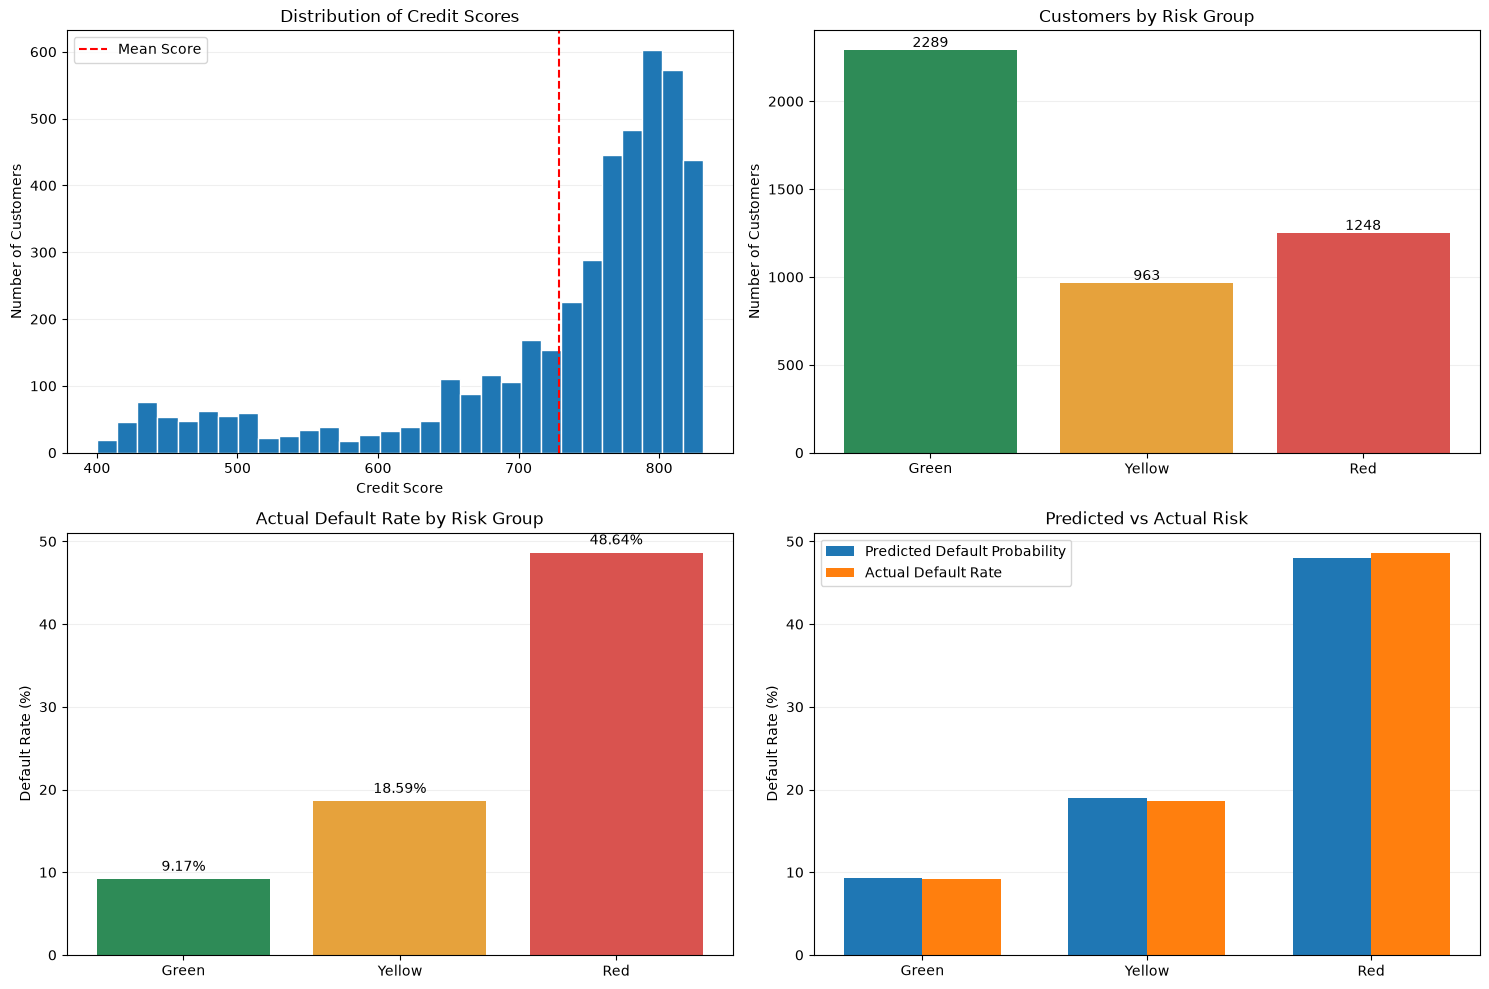

===== CREDIT SCORING VISUALIZATION =====
Đã lưu biểu đồ: C:\CreditAI_Project_Starter\CreditAI_Project\reports\figures\17_credit_scoring_dashboard.png
CELL 3 HOÀN THÀNH!


In [3]:

# =========================================================
# CELL 3: CREDIT SCORING VISUALIZATION
# =========================================================

# Sử dụng kết quả từ Cell 2
group_order = ["Green", "Yellow", "Red"]
group_colors = {
    "Green": "#2E8B57",
    "Yellow": "#E6A23C",
    "Red": "#D9534F"
}

fig, axes = plt.subplots(2, 2, figsize=(15, 10))

# 1. Phân bố điểm tín dụng
axes[0, 0].hist(
    scoring_results["Credit_Score"],
    bins=30,
    edgecolor="white"
)

axes[0, 0].axvline(
    scoring_results["Credit_Score"].mean(),
    color="red",
    linestyle="--",
    label="Mean Score"
)

axes[0, 0].set_title("Distribution of Credit Scores")
axes[0, 0].set_xlabel("Credit Score")
axes[0, 0].set_ylabel("Number of Customers")
axes[0, 0].legend()

# 2. Số khách hàng theo nhóm rủi ro
counts = risk_summary["So_khach_hang"]

axes[0, 1].bar(
    group_order,
    counts,
    color=[group_colors[g] for g in group_order]
)

axes[0, 1].set_title("Customers by Risk Group")
axes[0, 1].set_ylabel("Number of Customers")

for i, value in enumerate(counts):
    axes[0, 1].text(
        i, value + 20, str(int(value)),
        ha="center"
    )

# 3. Tỷ lệ default thực tế
actual_rates = risk_summary["Ty_le_default_thuc_te_%"]

axes[1, 0].bar(
    group_order,
    actual_rates,
    color=[group_colors[g] for g in group_order]
)

axes[1, 0].set_title("Actual Default Rate by Risk Group")
axes[1, 0].set_ylabel("Default Rate (%)")

for i, value in enumerate(actual_rates):
    axes[1, 0].text(
        i, value + 1, f"{value:.2f}%",
        ha="center"
    )

# 4. So sánh dự đoán và thực tế
x = np.arange(len(group_order))
width = 0.35

predicted_rates = (
    risk_summary["Xac_suat_default_TB"] * 100
)

axes[1, 1].bar(
    x - width / 2,
    predicted_rates,
    width,
    label="Predicted Default Probability"
)

axes[1, 1].bar(
    x + width / 2,
    actual_rates,
    width,
    label="Actual Default Rate"
)

axes[1, 1].set_xticks(x)
axes[1, 1].set_xticklabels(group_order)
axes[1, 1].set_title("Predicted vs Actual Risk")
axes[1, 1].set_ylabel("Default Rate (%)")
axes[1, 1].legend()

for ax in axes.flat:
    ax.grid(axis="y", alpha=0.2)
    ax.set_axisbelow(True)

plt.tight_layout()

figure_path = (
    FIGURES_DIR / "17_credit_scoring_dashboard.png"
)

plt.savefig(
    figure_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("===== CREDIT SCORING VISUALIZATION =====")
print("Đã lưu biểu đồ:", figure_path)
print("CELL 3 HOÀN THÀNH!")
